In [1]:
# Theory

# Support Vector Machines can be used for classification, regression and novelty detection. For
# classification, SVC finds a boundary that separates classes with a large margin. Support
# vectors are training observations that help determine the fitted boundary. A kernel allows the
# model to represent relationships that are not linear in the inputs. The radial basis function,
# or RBF kernel, is used in this experiment. Feature scaling is important because SVM models
# depend on distances between observations. A pipeline fits the scaler on training data and
# applies that transformation to test data. Iris flower measurements are used to demonstrate
# multiclass classification. Accuracy and the classification report assess predictions on unseen
# flowers.

# Support Vector Regression, or SVR, predicts continuous target values. SVR allows errors within
# an epsilon tolerance while controlling model complexity. The C parameter controls the penalty
# associated with errors beyond that tolerance. A noisy sine curve provides a small nonlinear
# regression dataset. MSE measures squared prediction error, while R2 evaluates explained
# variation. The SVR graph compares the observed values with the fitted prediction curve.

# One-Class SVM learns the region occupied by normal training observations. New observations
# receive label 1 for normal or -1 for an outlier. The nu parameter influences the fitted
# boundary; it is not a guaranteed test outlier rate. Here, normal training values are near zero
# and distant test values illustrate anomalies. Applications include flower classification,
# continuous forecasting and fault detection.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC, SVR, OneClassSVM
from sklearn.metrics import accuracy_score, classification_report, mean_squared_error, r2_score

In [3]:
# SVM classification on Iris flowers
X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
classifier = make_pipeline(StandardScaler(), SVC(kernel='rbf'))
classifier.fit(X_train, y_train)
prediction = classifier.predict(X_test)
print("SVM Accuracy:", accuracy_score(y_test, prediction) * 100)
print(classification_report(y_test, prediction))

SVM Accuracy: 96.66666666666667
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      0.90      0.95        10
           2       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [4]:
# SVR predicts a simple curved relationship
rng = np.random.default_rng(42)
X = np.linspace(0, 6, 80).reshape(-1, 1)
y = np.sin(X[:, 0]) + rng.normal(0, 0.1, 80)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
regressor = make_pipeline(StandardScaler(), SVR(kernel='rbf', C=10))
regressor.fit(X_train, y_train)
prediction = regressor.predict(X_test)
print("SVR MSE:", mean_squared_error(y_test, prediction))
print("SVR R2:", r2_score(y_test, prediction))

SVR MSE: 0.011139400875558765
SVR R2: 0.9785380797478931


In [5]:
# Learn normal values, then check new points for outliers
normal = rng.normal(0, 0.3, (100, 1))
points = np.array([[-3], [-0.1], [0.1], [3]])
detector = make_pipeline(StandardScaler(), OneClassSVM(nu=0.05))
detector.fit(normal)
print("Outlier labels (1 = normal, -1 = outlier):", detector.predict(points))

Outlier labels (1 = normal, -1 = outlier): [-1  1  1 -1]


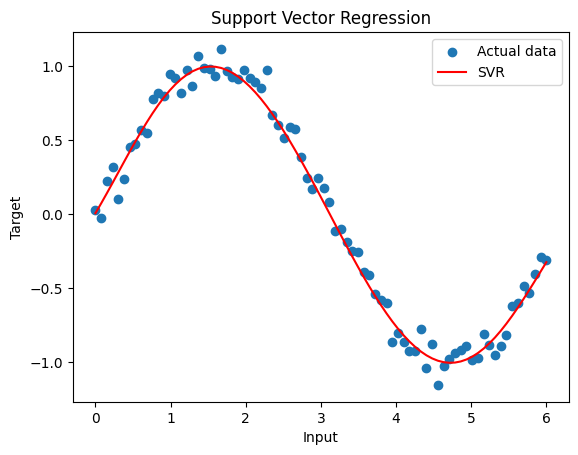

In [6]:
# Visualize the regression result
plt.scatter(X[:, 0], y, label='Actual data')
plt.plot(X[:, 0], regressor.predict(X), color='red', label='SVR')
plt.xlabel("Input")
plt.ylabel("Target")
plt.title("Support Vector Regression")
plt.legend()
plt.show()